# 🏠 House Price Prediction — Ames, Iowa

Notebook ini membangun dan membandingkan tiga model regresi — **Lasso Regression**, **Random Forest**, dan **LightGBM** — untuk memprediksi harga jual rumah (`SalePrice`), lalu mengevaluasinya dengan **R²** dan **RMSE**.

**Alur notebook**
1. Membaca dataset
2. Eksplorasi data (EDA)
3. Pembersihan data
4. Pipeline preprocessing
5. Pelatihan & perbandingan model (5-fold cross-validation + hold-out)
6. Pemilihan model terbaik & interpretasi
7. Menyimpan pipeline + model dalam **satu artifact** (`models/house_price_pipeline.joblib`)
8. Prediksi `test.csv`
9. Prediksi harga **satu rumah baru**

> **Mata uang:** semua harga dalam **dolar AS (USD)**, nilai nominal transaksi tahun **2006–2010** (tidak disesuaikan inflasi).

## 1. Import library & konfigurasi

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from lightgbm import LGBMRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

from house_features import add_features, build_preprocessor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
DATA_DIR = Path("data")
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)
IMG_DIR = Path("images"); IMG_DIR.mkdir(exist_ok=True)

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__}")

pandas 3.0.5 | scikit-learn 1.9.1 | lightgbm 4.7.0


## 2. Membaca dataset

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("train:", train.shape, "| test:", test.shape)
print("Kolom target ada di test.csv?", "SalePrice" in test.columns)
train.head()

train: (1460, 81) | test: (1459, 80)
Kolom target ada di test.csv? False


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,...,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,...,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,...,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,...,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


- `train.csv` berisi 1.460 rumah dengan 79 fitur + `Id` + target `SalePrice`.
- `test.csv` berisi 1.459 rumah **tanpa** `SalePrice`, jadi tidak bisa dipakai untuk evaluasi. Evaluasi dilakukan dengan cross-validation pada `train.csv`, dan `test.csv` dipakai untuk menghasilkan prediksi.

## 3. Eksplorasi data (EDA)
### 3.1 Cakupan dataset & distribusi harga

In [3]:
print(f"Periode penjualan : {train.YrSold.min()}–{train.YrSold.max()}")
print(f"Jumlah neighborhood: {train.Neighborhood.nunique()}")
print(f"Tahun dibangun     : {train.YearBuilt.min()}–{train.YearBuilt.max()}")
train["SalePrice"].describe().apply(lambda v: f"{v:,.0f}")

Periode penjualan : 2006–2010
Jumlah neighborhood: 25
Tahun dibangun     : 1872–2010


count      1,460
mean     180,921
std       79,443
min       34,900
25%      129,975
50%      163,000
75%      214,000
max      755,000
Name: SalePrice, dtype: str

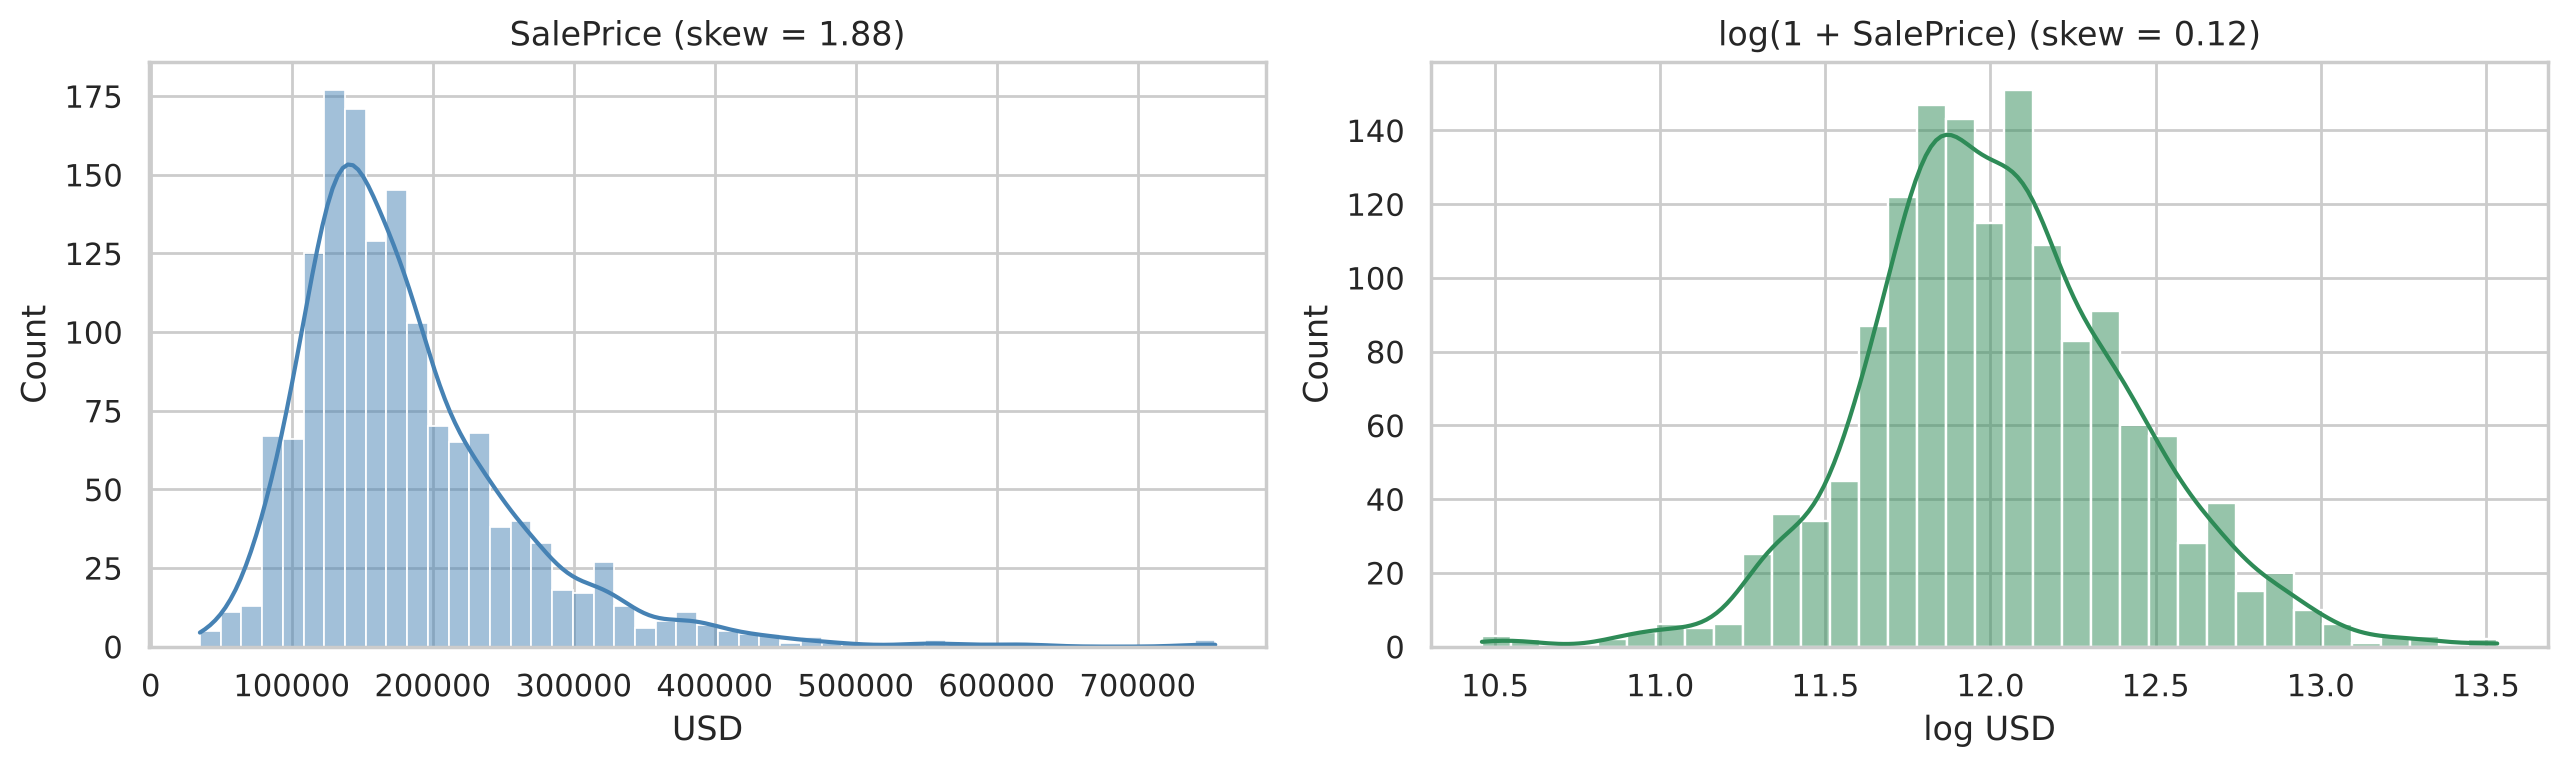

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set(title=f"SalePrice (skew = {train.SalePrice.skew():.2f})", xlabel="USD")
sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1], color="seagreen")
axes[1].set(title=f"log(1 + SalePrice) (skew = {np.log1p(train.SalePrice).skew():.2f})", xlabel="log USD")
plt.tight_layout(); plt.show()

Distribusi harga **condong ke kanan**. Model akan dilatih pada `log(1 + SalePrice)` agar error relatif diperlakukan setara untuk rumah murah dan mahal. Prediksi dikembalikan ke USD secara otomatis lewat `TransformedTargetRegressor`.

### 3.2 Fitur yang paling berkorelasi dengan harga

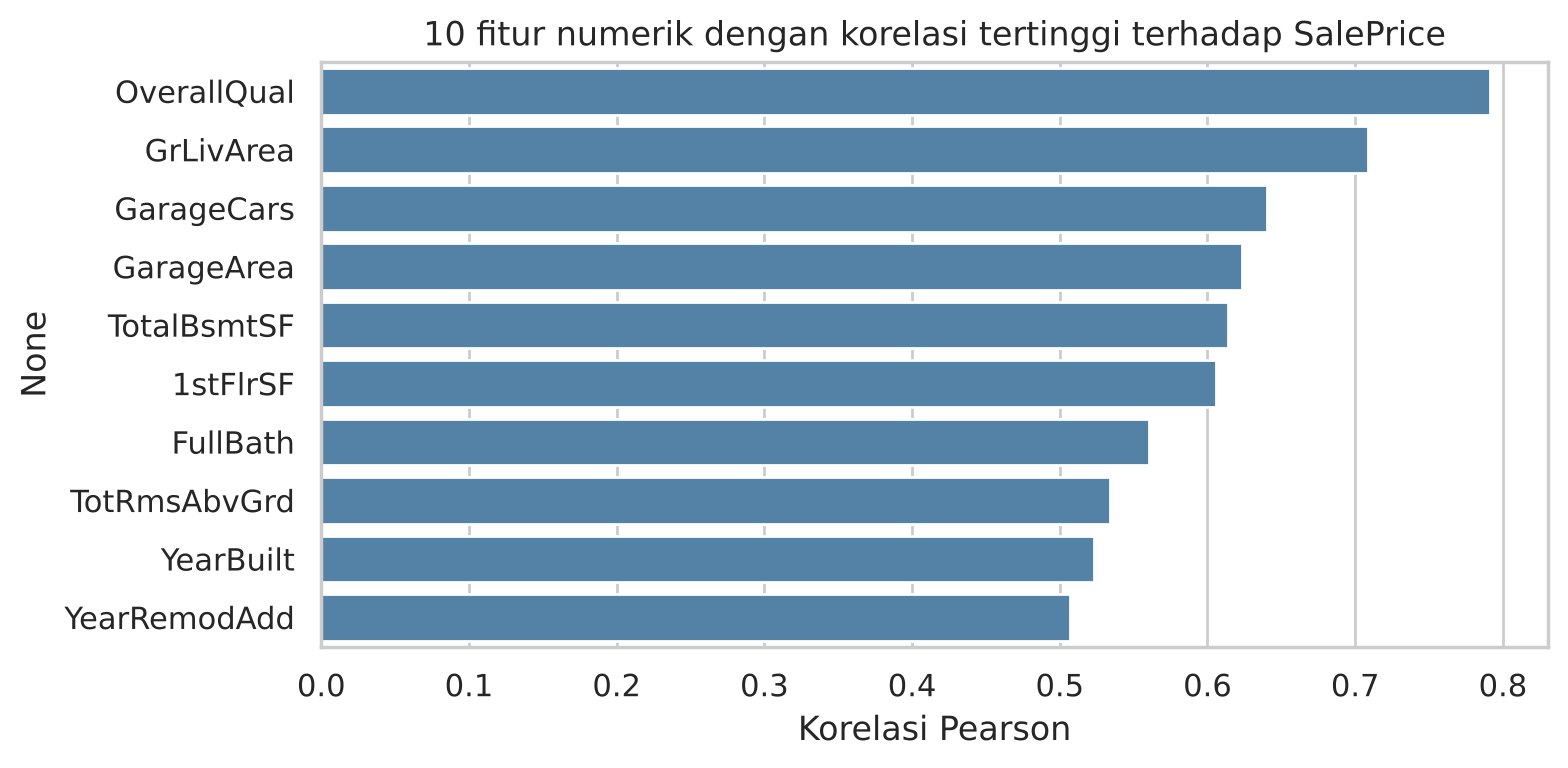

In [5]:
corr = train.select_dtypes("number").corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
top = corr.head(10)
plt.figure(figsize=(8, 4))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title("10 fitur numerik dengan korelasi tertinggi terhadap SalePrice")
plt.xlabel("Korelasi Pearson"); plt.tight_layout(); plt.show()

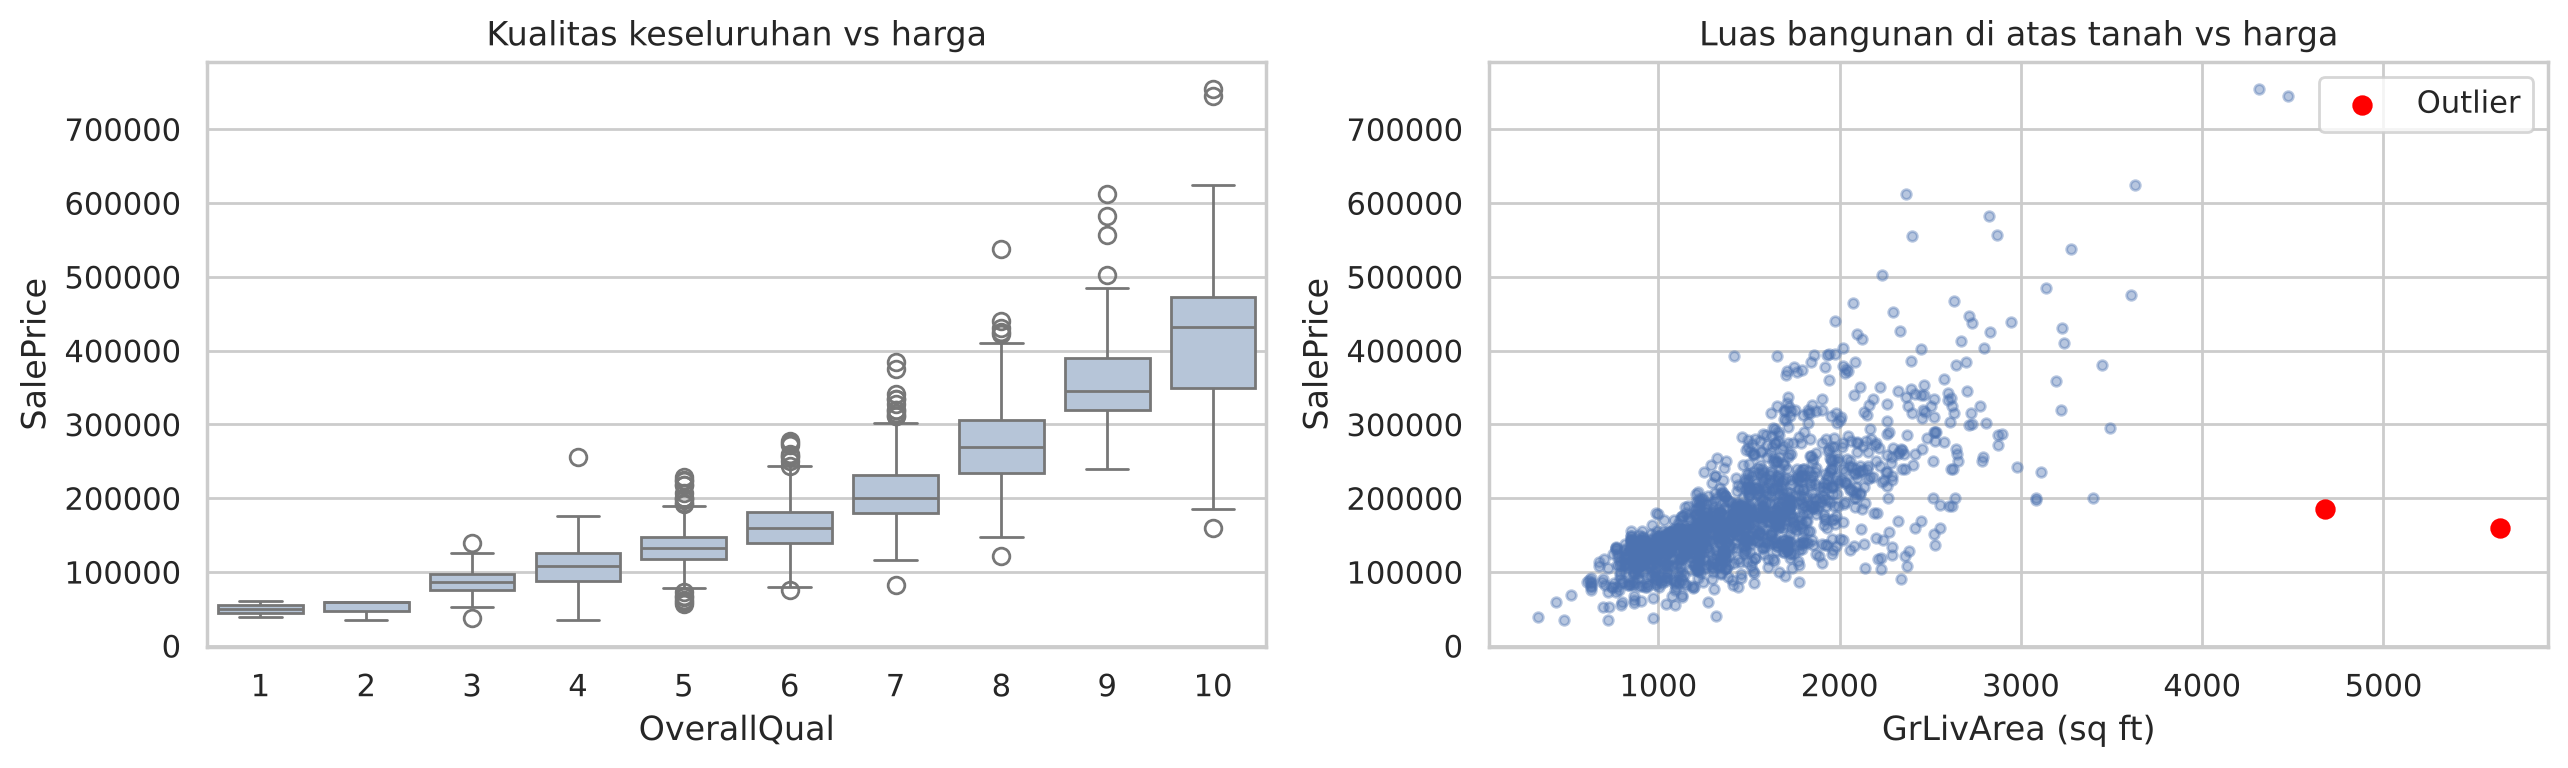

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[0], color="lightsteelblue")
axes[0].set_title("Kualitas keseluruhan vs harga")
outlier = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
axes[1].scatter(train.GrLivArea[~outlier], train.SalePrice[~outlier], alpha=0.4, s=12)
axes[1].scatter(train.GrLivArea[outlier], train.SalePrice[outlier], color="red", s=40, label="Outlier")
axes[1].set(title="Luas bangunan di atas tanah vs harga", xlabel="GrLivArea (sq ft)", ylabel="SalePrice")
axes[1].legend(); plt.tight_layout(); plt.show()

### 3.3 Missing values

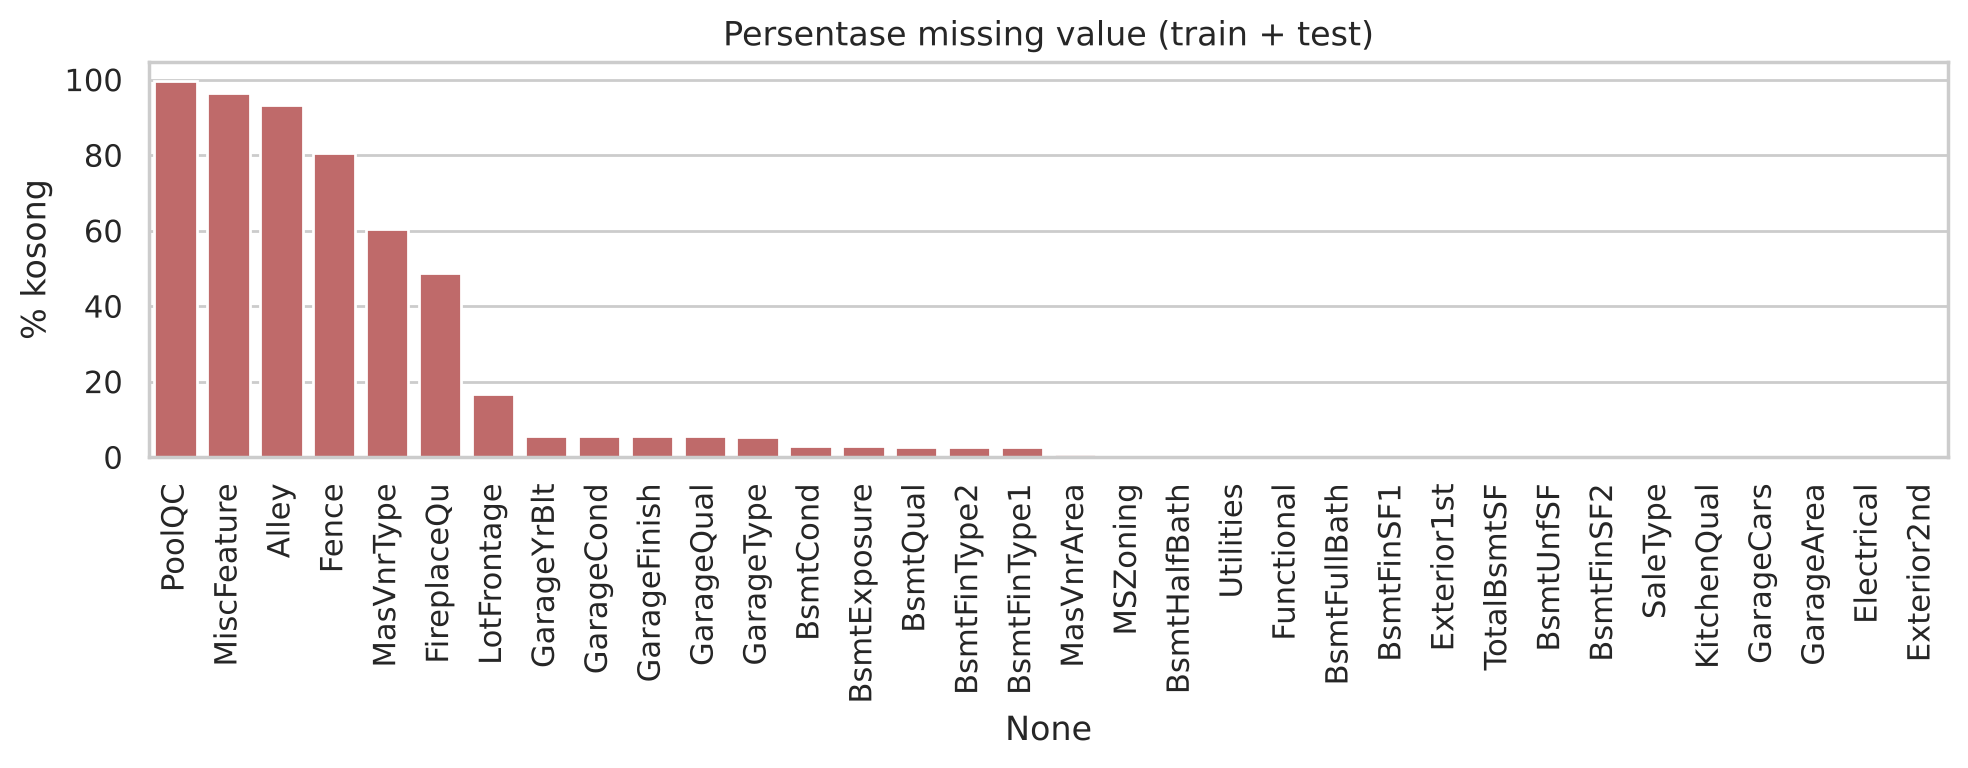

In [7]:
missing = pd.concat([train.drop(columns="SalePrice"), test]).isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
plt.figure(figsize=(10, 4))
sns.barplot(x=missing.index, y=missing.values * 100, color="indianred")
plt.xticks(rotation=90); plt.ylabel("% kosong"); plt.title("Persentase missing value (train + test)")
plt.tight_layout(); plt.show()

Sebagian besar nilai kosong **bukan data hilang**. Menurut deskripsi data, `NaN` pada `PoolQC`, `Alley`, `Fence`, `GarageType`, `BsmtQual`, dan kolom sejenis berarti rumah *tidak memiliki* fasilitas tersebut. Kolom-kolom ini diisi `"None"`. Sisanya (misalnya `LotFrontage`) diimputasi median/modus **di dalam pipeline**, sehingga nilai imputasi hanya dipelajari dari data latih.

## 4. Pembersihan data

In [8]:
outlier_mask = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)
print("Outlier yang dibuang:")
display(train.loc[outlier_mask, ["Id", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice"]])

train_clean = train.loc[~outlier_mask].reset_index(drop=True)
X = train_clean.drop(columns="SalePrice")
y = train_clean["SalePrice"]
print("Ukuran data latih setelah dibersihkan:", X.shape)

Outlier yang dibuang:


,Id,GrLivArea,OverallQual,SaleCondition,SalePrice
523,524,4676,10,Partial,184750
1298,1299,5642,10,Partial,160000


Ukuran data latih setelah dibersihkan: (1458, 80)


Dua rumah sangat besar (> 4.000 sq ft) dengan harga sangat rendah dibuang. Keduanya penjualan `Partial` yang tidak mewakili pasar normal dan direkomendasikan untuk dihapus oleh penyusun dataset (De Cock, 2011).

## 5. Pipeline preprocessing

Semua transformasi ada di `house_features.py` dan dibungkus dalam satu `sklearn.Pipeline`:

| Tahap | Isi |
|---|---|
| `add_features` | isi `"None"` untuk fasilitas yang tidak ada, ubah kode numerik kategorikal (`MSSubClass`, `MoSold`, `YrSold`) menjadi teks, skor ordinal kualitas, fitur baru (`TotalSF`, `TotalBath`, `HouseAge`, `YearsSinceRemod`, `QualxSF`, flag `Has*`), log-transform luas |
| Numerik | imputasi median → `StandardScaler` |
| Kategorikal | imputasi modus → `OneHotEncoder` (kategori langka < 5 digabung, kategori baru diabaikan) |

Pipeline ini ikut disimpan bersama model, jadi rumah baru diproses **persis sama** seperti data latih.

In [9]:
prep = build_preprocessor().fit(X)
X_prep = prep.transform(X)
print("Jumlah fitur setelah preprocessing:", X_prep.shape[1])
add_features(X.head(3))[["TotalSF", "TotalBath", "HouseAge", "YearsSinceRemod", "QualxSF"]]

Jumlah fitur setelah preprocessing: 327


,TotalSF,TotalBath,HouseAge,YearsSinceRemod,QualxSF
0,2566,3.5,5,5,17962
1,2524,2.5,31,31,15144
2,2706,3.5,7,6,18942


## 6. Pelatihan & perbandingan model
### 6.1 Definisi model

In [10]:
def make_pipeline(model):
    """Preprocessing + model, dilatih pada log(SalePrice) dan memprediksi dalam USD."""
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", build_preprocessor()), ("model", model)]),
        func=np.log1p, inverse_func=np.expm1,
    )

models = {
    "Lasso Regression": Lasso(alpha=0.0005, max_iter=50_000),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, max_features=0.3, n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": LGBMRegressor(
        n_estimators=2000, learning_rate=0.01, num_leaves=15, min_child_samples=10,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.4, reg_lambda=1.0,
        random_state=RANDOM_STATE, verbose=-1),
}

### 6.2 Evaluasi dengan 5-fold cross-validation
Setiap model dievaluasi dengan **R²**, **RMSE (USD)**, dan **RMSE pada log harga** (metrik kompetisi Kaggle). Pipeline dilatih ulang di setiap fold, jadi tidak ada kebocoran data dari fold validasi.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rmse_log = lambda est, X_, y_: -np.sqrt(mean_squared_error(np.log1p(y_), np.log1p(est.predict(X_))))
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "rmse_log": rmse_log}

rows = []
for name, model in models.items():
    res = cross_validate(make_pipeline(model), X, y, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "R² (CV)": res["test_r2"].mean(),
        "R² std": res["test_r2"].std(),
        "RMSE USD (CV)": -res["test_rmse"].mean(),
        "RMSE std": res["test_rmse"].std(),
        "RMSE log (CV)": -res["test_rmse_log"].mean(),
        "Waktu fit (s)": res["fit_time"].mean(),
    })
    print(f"{name:17s} R² = {rows[-1]['R² (CV)']:.4f}  RMSE = ${rows[-1]['RMSE USD (CV)']:,.0f}")

cv_results = pd.DataFrame(rows).sort_values("RMSE USD (CV)").reset_index(drop=True)
cv_results.style.format({"R² (CV)": "{:.4f}", "R² std": "{:.4f}", "RMSE USD (CV)": "${:,.0f}",
                         "RMSE std": "${:,.0f}", "RMSE log (CV)": "{:.4f}", "Waktu fit (s)": "{:.2f}"})

Lasso Regression  R² = 0.9376  RMSE = $19,665


Random Forest     R² = 0.9001  RMSE = $25,050


LightGBM          R² = 0.9245  RMSE = $21,808


,Model,R² (CV),R² std,RMSE USD (CV),RMSE std,RMSE log (CV),Waktu fit (s)
0,Lasso Regression,0.9376,0.0115,"$19,665","$1,683",0.1091,0.27
1,LightGBM,0.9245,0.0077,"$21,808","$2,206",0.1164,1.32
2,Random Forest,0.9001,0.0071,"$25,050","$1,865",0.1304,0.96


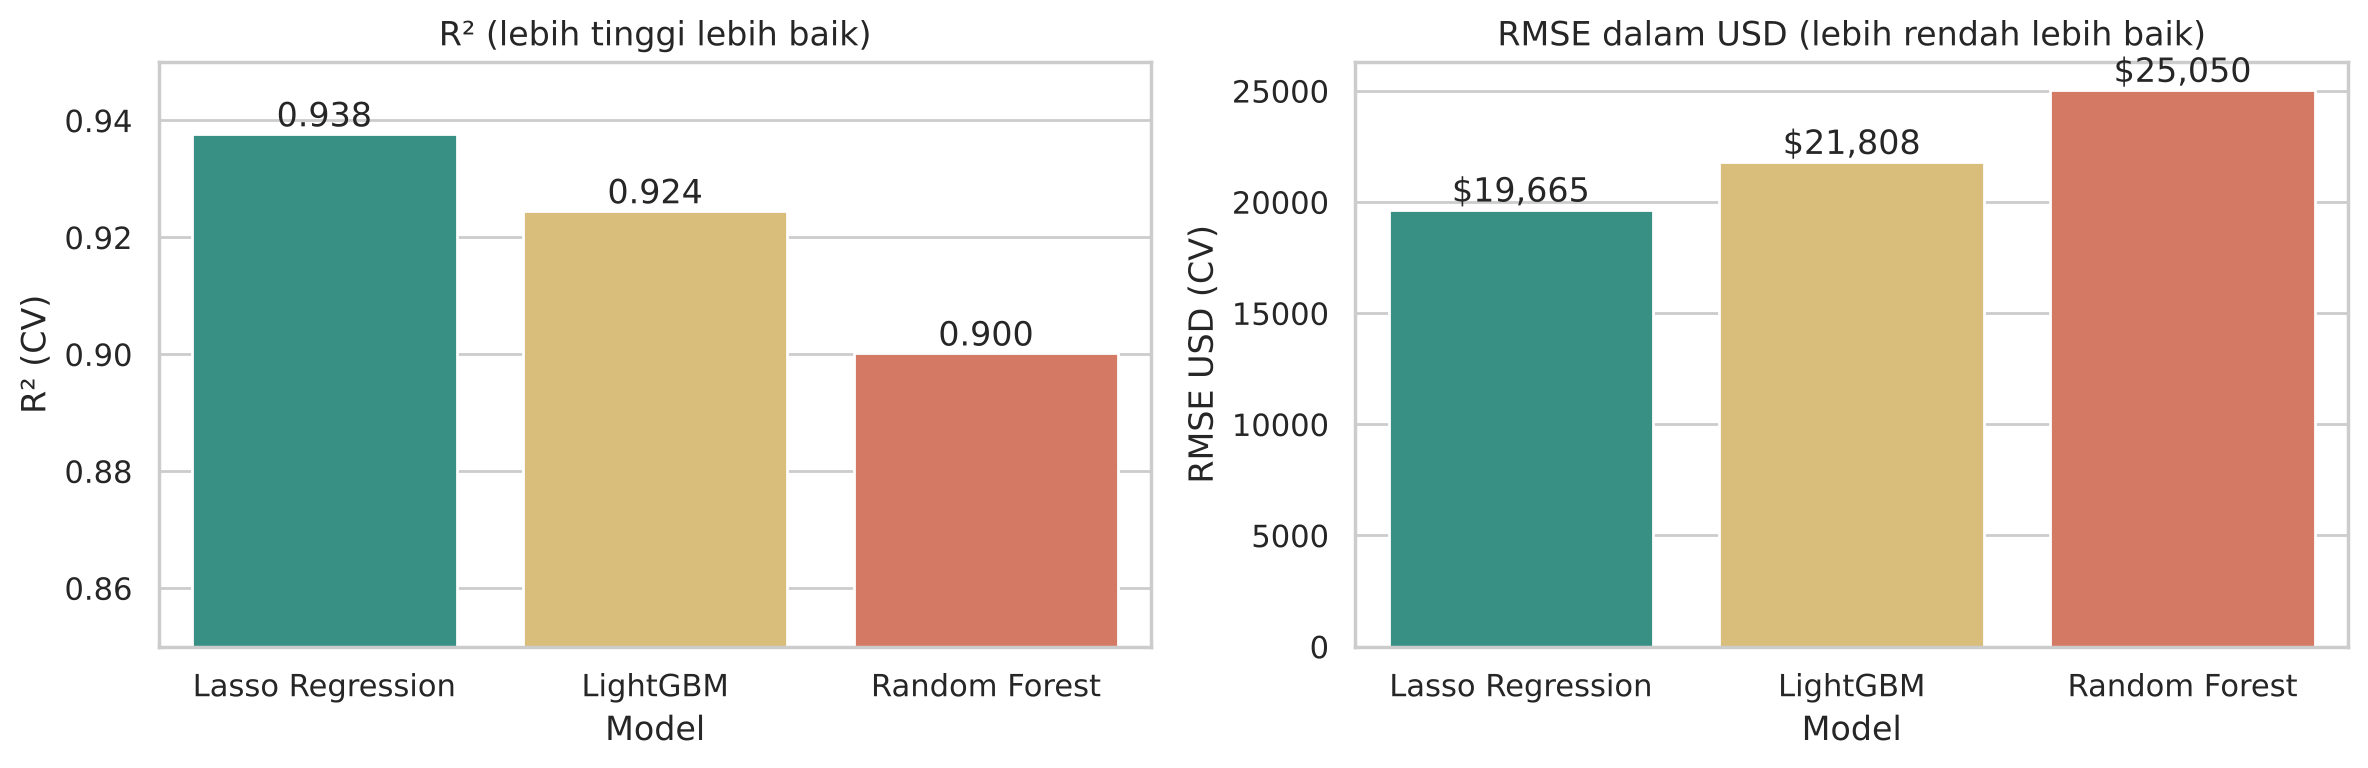

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
palette = dict(zip(cv_results["Model"], ["#2a9d8f", "#e9c46a", "#e76f51"]))
sns.barplot(data=cv_results, x="Model", y="R² (CV)", ax=axes[0], palette=palette)
axes[0].set(ylim=(0.85, 0.95), title="R² (lebih tinggi lebih baik)")
sns.barplot(data=cv_results, x="Model", y="RMSE USD (CV)", ax=axes[1], palette=palette)
axes[1].set(title="RMSE dalam USD (lebih rendah lebih baik)")
for ax, col, fmt in [(axes[0], "R² (CV)", "{:.3f}"), (axes[1], "RMSE USD (CV)", "${:,.0f}")]:
    for i, v in enumerate(cv_results[col]):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(IMG_DIR / "model_comparison.png", dpi=120); plt.show()

### 6.3 Validasi hold-out (80/20)
Sebagai pemeriksaan kedua, setiap model dilatih pada 80% data dan diuji pada 20% data yang belum pernah dilihat.

In [13]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

holdout, val_preds = [], {}
for name, model in models.items():
    pipe = make_pipeline(model).fit(X_tr, y_tr)
    pred = pipe.predict(X_val)
    val_preds[name] = pred
    holdout.append({"Model": name,
                    "R² (hold-out)": r2_score(y_val, pred),
                    "RMSE USD (hold-out)": np.sqrt(mean_squared_error(y_val, pred)),
                    "MAPE (hold-out)": np.mean(np.abs(pred - y_val) / y_val)})
holdout = pd.DataFrame(holdout).sort_values("RMSE USD (hold-out)").reset_index(drop=True)
holdout.style.format({"R² (hold-out)": "{:.4f}", "RMSE USD (hold-out)": "${:,.0f}", "MAPE (hold-out)": "{:.1%}"})

,Model,R² (hold-out),RMSE USD (hold-out),MAPE (hold-out)
0,Lasso Regression,0.9394,"$18,298",7.9%
1,LightGBM,0.9355,"$18,874",8.5%
2,Random Forest,0.9120,"$22,051",9.7%


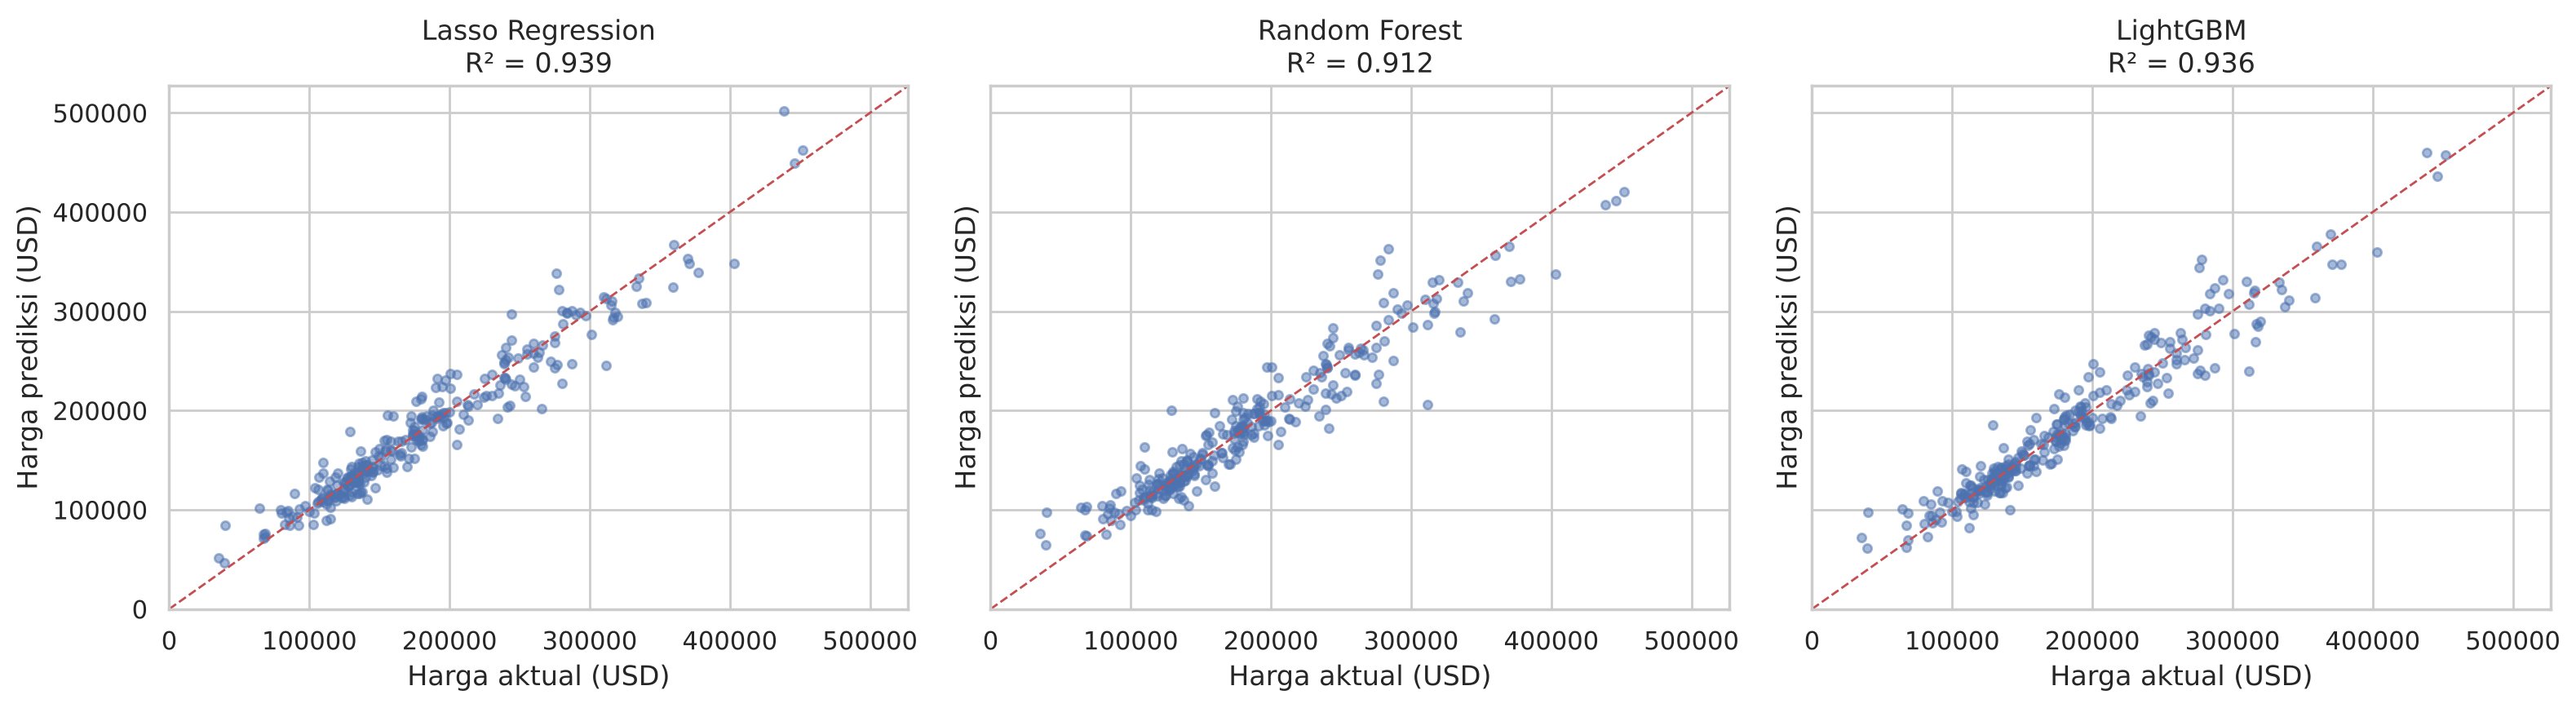

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
lim = [0, max(y_val.max(), max(p.max() for p in val_preds.values())) * 1.05]
for ax, (name, pred) in zip(axes, val_preds.items()):
    ax.scatter(y_val, pred, alpha=0.5, s=14)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set(title=f"{name}\nR² = {r2_score(y_val, pred):.3f}", xlabel="Harga aktual (USD)",
           ylabel="Harga prediksi (USD)", xlim=lim, ylim=lim)
plt.tight_layout(); plt.savefig(IMG_DIR / "actual_vs_predicted.png", dpi=120); plt.show()

## 7. Model terpilih
Model dipilih berdasarkan **RMSE cross-validation terendah**, karena CV lebih stabil daripada satu split hold-out.

In [15]:
best_name = cv_results.loc[0, "Model"]
print(f"Model terpilih: {best_name}")
print(f"  R² (CV)   : {cv_results.loc[0, 'R² (CV)']:.4f}")
print(f"  RMSE (CV) : ${cv_results.loc[0, 'RMSE USD (CV)']:,.0f}")

final_pipeline = make_pipeline(models[best_name]).fit(X, y)  # latih ulang pada seluruh data latih

Model terpilih: Lasso Regression
  R² (CV)   : 0.9376
  RMSE (CV) : $19,665


**Kenapa Lasso bisa mengalahkan model berbasis pohon?** Hubungan antara harga (dalam skala log) dan fitur utama seperti luas, kualitas, dan umur cukup linear setelah feature engineering dan log-transform. Penalti L1 pada Lasso juga membuang fitur yang tidak berguna. Dengan hanya ~1.460 baris, model linear yang teregulasi cenderung lebih stabil dibanding model pohon yang butuh lebih banyak data untuk mempelajari interaksi.

### 7.1 Interpretasi model

Lasso memakai 116 dari 327 fitur (sisanya bernilai nol).


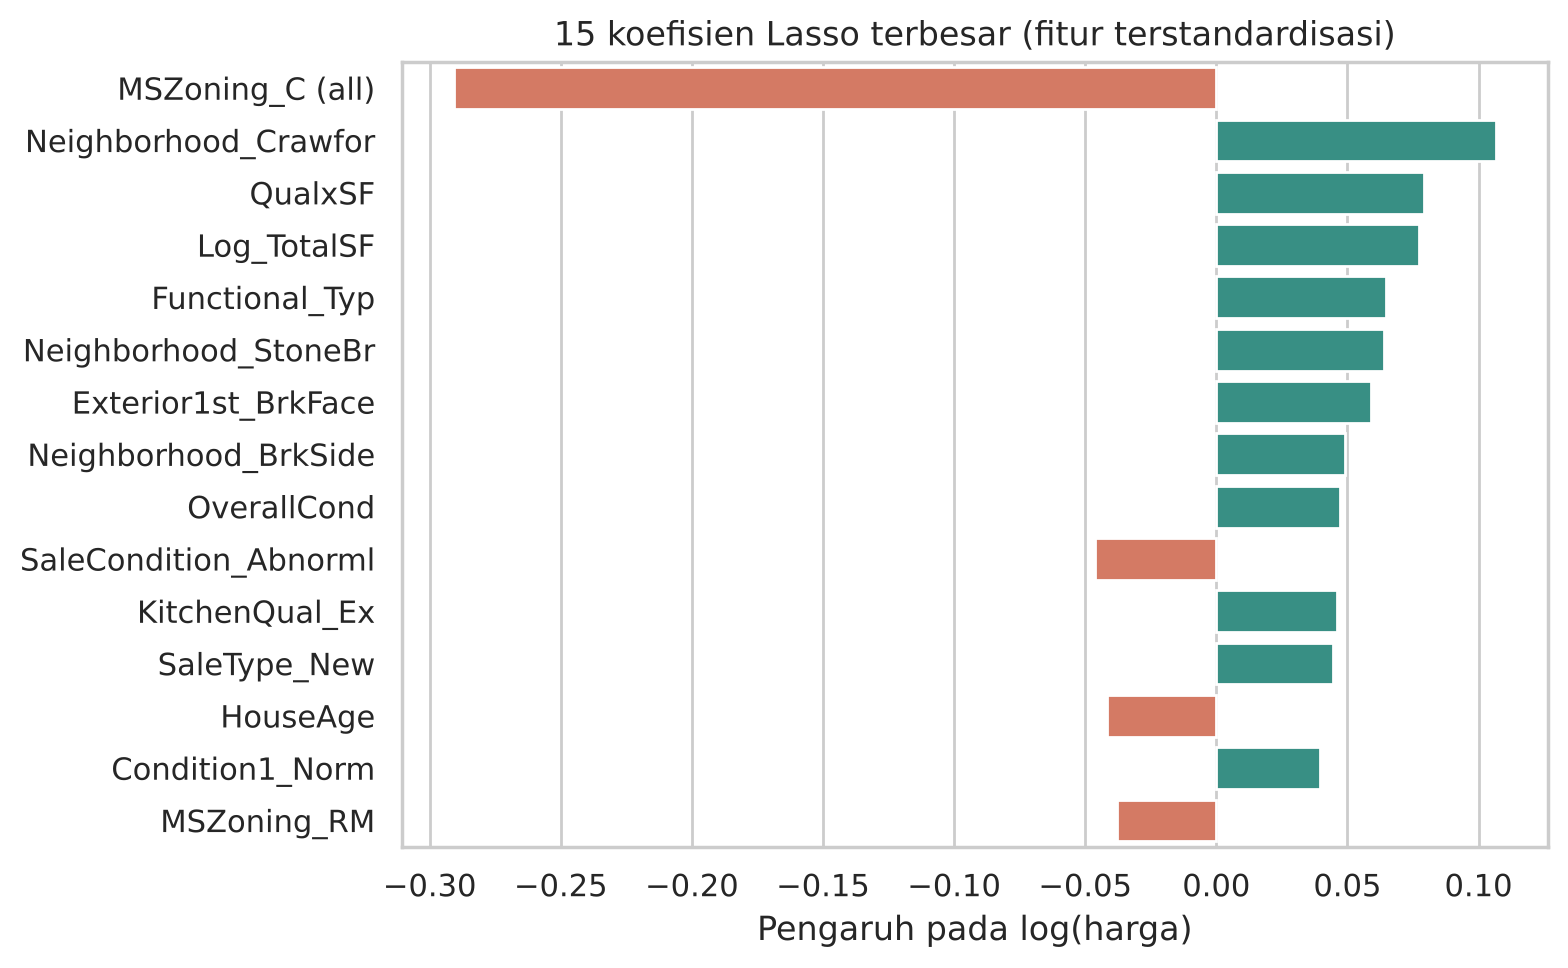

In [16]:
reg = final_pipeline.regressor_
feature_names = reg.named_steps["prep"].named_steps["encode"].get_feature_names_out()
est = reg.named_steps["model"]

if hasattr(est, "coef_"):
    imp = pd.Series(est.coef_, index=feature_names)
    print(f"Lasso memakai {(imp != 0).sum()} dari {len(imp)} fitur (sisanya bernilai nol).")
    top_imp = imp.reindex(imp.abs().sort_values(ascending=False).index).head(15)
    title, xlabel = "15 koefisien Lasso terbesar (fitur terstandardisasi)", "Pengaruh pada log(harga)"
else:
    top_imp = pd.Series(est.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
    title, xlabel = "15 fitur terpenting", "Importance"

plt.figure(figsize=(8, 5))
sns.barplot(x=top_imp.values, y=top_imp.index, palette=["#2a9d8f" if v > 0 else "#e76f51" for v in top_imp.values])
plt.title(title); plt.xlabel(xlabel); plt.ylabel(""); plt.tight_layout()
plt.savefig(IMG_DIR / "feature_importance.png", dpi=120); plt.show()

Koefisien positif (hijau) menaikkan harga, negatif (oranye) menurunkannya. Karena target dalam skala log, koefisien 0,05 kira-kira berarti **+5% harga**: untuk fitur numerik (terstandardisasi) per kenaikan satu standar deviasi, untuk fitur kategorikal (0/1) bila rumah termasuk kategori tersebut. Contoh: zona komersial `MSZoning_C (all)` menurunkan harga sekitar 25%.

## 8. Menyimpan pipeline + model dalam satu artifact

Satu file `models/house_price_pipeline.joblib` berisi:
- `pipeline`: preprocessing + model + transformasi balik log → USD
- `metadata`: mata uang, cakupan dataset, metrik, nilai default untuk fitur yang tidak diisi, dan rentang nilai fitur

Demo interaktif (`app.py`) hanya memuat file ini, sehingga input rumah baru melewati preprocessing yang sama persis dengan saat pelatihan.

In [17]:
raw_features = X.columns.tolist()

# Nilai default = rumah "tipikal" di data latih (median untuk numerik, modus untuk kategorikal).
template = {}
for col in raw_features:
    if pd.api.types.is_numeric_dtype(X[col]):
        template[col] = float(X[col].median())
    else:
        template[col] = X[col].value_counts(dropna=False).idxmax()
        if pd.isna(template[col]):
            template[col] = None

DEMO_NUMERIC = ["OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd", "1stFlrSF", "2ndFlrSF",
                "TotalBsmtSF", "LotArea", "GarageCars", "GarageArea", "FullBath", "HalfBath",
                "BedroomAbvGr", "TotRmsAbvGrd", "Fireplaces", "YrSold"]
feature_ranges = {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                      "p01": float(X[c].quantile(0.01)), "p99": float(X[c].quantile(0.99))}
                  for c in DEMO_NUMERIC}

metadata = {
    "model_name": best_name,
    "target": "SalePrice",
    "currency": "USD",
    "price_basis": "Harga jual nominal saat transaksi (tidak disesuaikan inflasi)",
    "dataset": {
        "name": "Ames Housing (Kaggle: House Prices - Advanced Regression Techniques)",
        "location": "Ames, Iowa, Amerika Serikat",
        "sale_years": [int(X.YrSold.min()), int(X.YrSold.max())],
        "year_built": [int(X.YearBuilt.min()), int(X.YearBuilt.max())],
        "n_train_rows": int(len(X)),
        "price_min": float(y.min()), "price_median": float(y.median()), "price_max": float(y.max()),
        "price_quantiles": [float(v) for v in y.quantile(np.linspace(0, 1, 101))],
        "area_unit": "square feet (1 sq ft = 0,0929 m²)",
    },
    "metrics_cv": cv_results.set_index("Model").round(4).to_dict(orient="index"),
    "metrics_holdout": holdout.set_index("Model").round(4).to_dict(orient="index"),
    "raw_features": raw_features,
    "template": template,
    "feature_ranges": feature_ranges,
    "categories": {c: sorted(X[c].dropna().unique().tolist())
                   for c in ["Neighborhood", "MSZoning", "KitchenQual", "ExterQual", "BsmtQual", "CentralAir", "BldgType"]},
    "versions": {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__, "pandas": pd.__version__},
}

artifact_path = MODEL_DIR / "house_price_pipeline.joblib"
joblib.dump({"pipeline": final_pipeline, "metadata": metadata}, artifact_path, compress=3)
print(f"Tersimpan: {artifact_path} ({artifact_path.stat().st_size / 1024:.0f} KB)")

Tersimpan: models/house_price_pipeline.joblib (10 KB)


## 9. Prediksi `test.csv`
Artifact yang baru disimpan dimuat ulang untuk memastikan file tersebut bisa dipakai secara mandiri.

In [18]:
artifact = joblib.load(artifact_path)
pipe = artifact["pipeline"]

test_pred = pipe.predict(test)
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": test_pred.round(0)})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
print(submission["SalePrice"].describe().apply(lambda v: f"{v:,.0f}"))
submission.head()

(1459, 2)
count        1,459
mean       178,967
std         82,916
min         41,733
25%        126,208
50%        157,844
75%        210,270
max      1,321,335
Name: SalePrice, dtype: str


,Id,SalePrice
0,1461,119122.0
1,1462,156606.0
2,1463,183466.0
3,1464,202191.0
4,1465,190579.0


## 10. Prediksi harga satu rumah baru
Cukup isi fitur yang diketahui. Fitur lain diisi nilai rumah tipikal (`template`) dari artifact.

In [19]:
def predict_house(artifact, **features):
    meta = artifact["metadata"]
    row = {**meta["template"], **features}
    house = pd.DataFrame([row])[meta["raw_features"]]
    return float(artifact["pipeline"].predict(house)[0])

new_house = dict(
    Neighborhood="CollgCr", OverallQual=7, OverallCond=5,
    YearBuilt=2005, YearRemodAdd=2005, YrSold=2010,
    **{"1stFlrSF": 1100, "2ndFlrSF": 800}, GrLivArea=1900, TotalBsmtSF=1100,
    LotArea=9000, GarageCars=2, GarageArea=500, FullBath=2, HalfBath=1,
    BedroomAbvGr=3, TotRmsAbvGrd=8, Fireplaces=1, KitchenQual="Gd", ExterQual="Gd",
)
price = predict_house(artifact, **new_house)
rmse = artifact["metadata"]["metrics_cv"][artifact["metadata"]["model_name"]]["RMSE USD (CV)"]
print(f"Estimasi harga : ${price:,.0f} USD")
print(f"Rentang kasar  : ${price - rmse:,.0f} – ${price + rmse:,.0f} (± 1 RMSE CV)")

Estimasi harga : $212,857 USD
Rentang kasar  : $193,192 – $232,522 (± 1 RMSE CV)


## 11. Kesimpulan

- Ketiga model menjelaskan **>90% variasi harga** (R²).
- Model terpilih adalah **Lasso Regression**. RMSE cross-validation-nya terendah (sekitar \$19–20 ribu, setara ~11% dari median harga), sekaligus paling cepat dan paling mudah diinterpretasi.
- LightGBM berada di posisi kedua, Random Forest ketiga.
- Pipeline lengkap disimpan sebagai satu artifact dan dipakai oleh demo interaktif `app.py`.

**Keterbatasan**: lihat bagian *Keterbatasan* di `README.md`. Ringkasnya: data hanya mencakup satu kota di AS pada 2006–2010, harga belum disesuaikan inflasi, dan prediksi kurang andal untuk rumah di luar rentang data latih.